# 02 Delivery-time regression
Goal: predict `delivery_minutes` for a new order **at the moment it is placed**.

In [3]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.cleaning import clean_customers, clean_orders

SEED = 42
customers, _ = clean_customers(pd.read_csv('C:\\Users\\lakshraj computer\\Downloads\\QuickCart_Assessment_Keval_Chauhan\\quickcart_data\\customers.csv'))
orders, _ = clean_orders(pd.read_csv('C:\\Users\\lakshraj computer\\Downloads\\QuickCart_Assessment_Keval_Chauhan\\quickcart_data\\orders.csv'))
df = orders.merge(customers[['customer_id', 'city']], on='customer_id', how='left')
df = df[df['delivery_minutes'].notna()].copy()   # cancelled orders and flagged outliers have no usable target
print(df.shape)

(101299, 16)


## 1. Feature engineering
Only information known when the order is placed is used: distance, items, store load, rain, basket, discount, payment method and city. `status` and `delivery_minutes` are never used as inputs, and IDs are dropped.

Features built from `order_ts`:
- **`is_peak_hour`** (8–9 and 19–21): breakfast and dinner rushes overload dark stores and riders. Part C showed these hours add about 4 minutes, a step change that a smooth hour curve cannot capture.
- **`hour_sin` / `hour_cos`**: hour of day as a circle, so 23:00 and 00:00 are close together.
- **`is_weekend`**: tests whether weekend demand patterns matter (Part C suggested they do not).

In [4]:
ts = df['order_ts']
hour = ts.dt.hour + ts.dt.minute / 60
df['hour_sin'] = np.sin(2 * np.pi * hour / 24)
df['hour_cos'] = np.cos(2 * np.pi * hour / 24)
df['is_peak_hour'] = ts.dt.hour.isin([8, 9, 19, 20, 21]).astype(int)
df['is_weekend'] = (ts.dt.dayofweek >= 5).astype(int)

NUM = ['distance_km', 'items_count', 'store_open_orders', 'basket_value', 'discount_amt', 'hour_sin', 'hour_cos']
BIN = ['is_raining', 'is_peak_hour', 'is_weekend']
CAT = ['payment_method', 'city']

X, y = df[NUM + BIN + CAT], df['delivery_minutes']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM),
    ('bin', 'passthrough', BIN),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(drop='first', handle_unknown='ignore'))]), CAT)])

make = lambda model: Pipeline([('pre', pre), ('model', model)])

def score(name, fitted):
    p = fitted.predict(X_te)
    return {'model': name, 'MAE': mean_absolute_error(y_te, p), 'RMSE': mean_squared_error(y_te, p) ** 0.5}

## 2. Baselines

In [5]:
mean_base = make(DummyRegressor(strategy='mean')).fit(X_tr, y_tr)
linreg = make(LinearRegression()).fit(X_tr, y_tr)
results = [score('Mean baseline', mean_base), score('Linear Regression', linreg)]
pd.DataFrame(results).round(3)

,model,MAE,RMSE
0,Mean baseline,5.884,7.487
1,Linear Regression,2.803,3.500


**Result:** Linear Regression cuts MAE from 5.88 to 2.80 minutes (RMSE 7.49 to 3.50), so the order features explain most of the variation.

## 3. Regularisation (5-fold CV on the training set)

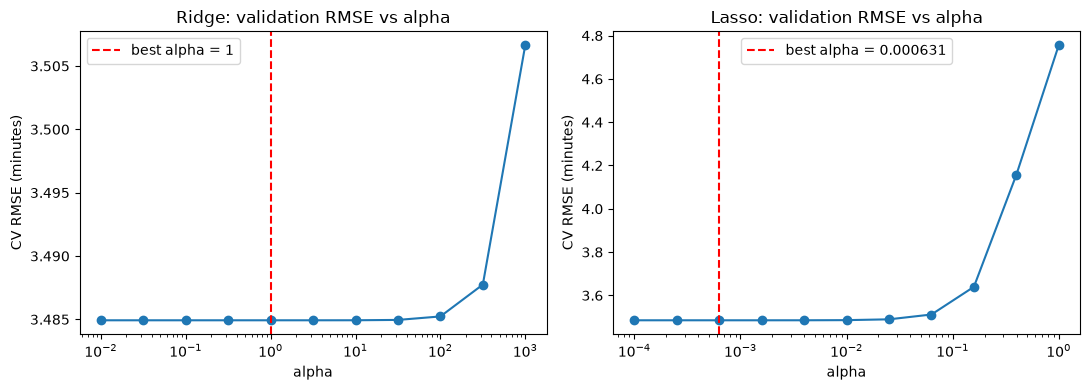

,model,MAE,RMSE
0,Mean baseline,5.884,7.487
1,Linear Regression,2.803,3.500
2,Ridge (tuned),2.803,3.500
3,Lasso (tuned),2.803,3.500


In [6]:
cv = KFold(5, shuffle=True, random_state=SEED)
grids = {'Ridge': (Ridge(), np.logspace(-2, 3, 11)), 'Lasso': (Lasso(max_iter=10000), np.logspace(-4, 0, 11))}
searches = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, (est, alphas)) in zip(axes, grids.items()):
    gs = GridSearchCV(make(est), {'model__alpha': alphas}, cv=cv, scoring='neg_root_mean_squared_error').fit(X_tr, y_tr)
    searches[name] = gs
    ax.semilogx(alphas, -gs.cv_results_['mean_test_score'], marker='o')
    ax.axvline(gs.best_params_['model__alpha'], color='red', ls='--', label=f"best alpha = {gs.best_params_['model__alpha']:.3g}")
    ax.set(title=f'{name}: validation RMSE vs alpha', xlabel='alpha', ylabel='CV RMSE (minutes)'); ax.legend()
plt.tight_layout(); plt.show()
for name, gs in searches.items():
    results.append(score(f'{name} (tuned)', gs.best_estimator_))
pd.DataFrame(results).round(3)

In [7]:
lasso = searches['Lasso'].best_estimator_
coefs = pd.Series(lasso['model'].coef_, index=lasso['pre'].get_feature_names_out())
print('Dropped to exactly zero:', list(coefs[coefs == 0].index))
coefs.round(3).sort_values(key=abs, ascending=False)

Dropped to exactly zero: ['num__basket_value', 'cat__payment_method_wallet']


bin__is_raining               6.491
num__distance_km              5.069
bin__is_peak_hour             3.980
cat__city_Bengaluru           3.209
num__store_open_orders        2.925
cat__city_Pune                1.200
num__items_count              0.995
cat__city_Surat              -0.810
cat__city_Jaipur             -0.446
cat__payment_method_card     -0.066
cat__payment_method_UPI      -0.022
num__hour_sin                -0.017
num__hour_cos                 0.014
bin__is_weekend               0.011
num__discount_amt            -0.006
num__basket_value            -0.000
cat__payment_method_wallet    0.000
dtype: float64

**Answer:** Best alphas are Ridge = 1.0 and Lasso = 0.0006, and both score the same as plain Linear Regression (CV RMSE 3.485). Validation error is flat for small alpha and only rises once alpha is large, so regularisation adds nothing here: there are about 80k rows and only 17 features with no strong collinearity, so plain Linear Regression is not overfitting.

Lasso sets exactly two coefficients to zero:
- **`basket_value`**: its small link to delivery time runs through `items_count`, which is already in the model, so it adds nothing extra.
- **`payment_method_wallet`**: wallet orders take the same time as the COD reference group, so the dummy carries no signal.

Several other features are shrunk to about 0 (`discount_amt`, `is_weekend`, `hour_sin`, `hour_cos`, UPI, card). The L1 penalty zeroes any feature whose error reduction is smaller than the penalty.

## 4. Non-linear model

In [8]:
hgb = make(HistGradientBoostingRegressor(random_state=SEED)).fit(X_tr, y_tr)
results.append(score('HistGradientBoosting', hgb))
comparison = pd.DataFrame(results).round(3); comparison

,model,MAE,RMSE
0,Mean baseline,5.884,7.487
1,Linear Regression,2.803,3.500
2,Ridge (tuned),2.803,3.500
3,Lasso (tuned),2.803,3.500
4,HistGradientBoosting,2.829,3.532


**Answer:** No. HistGradientBoosting (MAE 2.83, RMSE 3.53) is slightly worse than Linear Regression (MAE 2.80, RMSE 3.50). Part C showed delivery time is built from simple additive effects: a straight-line rise with distance and store load, plus fixed jumps for rain and peak hours. A linear model already captures these, so trees have no interactions or curves to find and only add variance. The remaining error (about 3.5 min) looks like random noise that no model can explain with these inputs.

## 5. Interpretation (unscaled effects from Linear Regression)

In [9]:
lr = linreg['model']
names = linreg['pre'].get_feature_names_out()
coef = pd.Series(lr.coef_, index=names)
sd = linreg['pre'].named_transformers_['num']['sc'].scale_
print(f"Rain:        {coef['bin__is_raining']:+.2f} min")
print(f"Per km:      {coef['num__distance_km'] / sd[NUM.index('distance_km')]:+.2f} min")
print(f"Peak hour:   {coef['bin__is_peak_hour']:+.2f} min")
print(f"Per open order at store: {coef['num__store_open_orders'] / sd[NUM.index('store_open_orders')]:+.2f} min")

Rain:        +6.50 min
Per km:      +3.10 min
Peak hour:   +3.98 min
Per open order at store: +0.35 min


**Answer:** Rain adds about **6.5 minutes** to a delivery, and each extra kilometre adds about **3.1 minutes**, holding everything else equal. Peak hours add about 4 minutes and each extra open order at the store adds about 0.35 minutes.

## 6. Errors

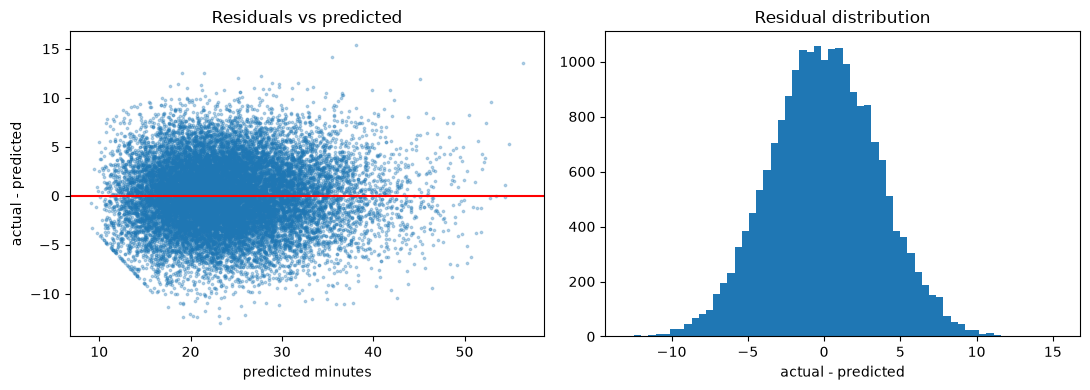

,worst 5% orders,all test orders
actual,25.03,24.11
distance_km,2.57,2.44
store_open_orders,15.43,15.07
is_raining,0.07,0.06
is_peak_hour,0.23,0.21
items_count,7.53,7.48


In [10]:
best = hgb
pred = best.predict(X_te)
err = X_te.assign(actual=y_te, pred=pred, resid=y_te - pred)
err['abs_err'] = err['resid'].abs()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(err['pred'], err['resid'], s=3, alpha=0.3); axes[0].axhline(0, color='red')
axes[0].set(title='Residuals vs predicted', xlabel='predicted minutes', ylabel='actual - predicted')
axes[1].hist(err['resid'], bins=60); axes[1].set(title='Residual distribution', xlabel='actual - predicted')
plt.tight_layout(); plt.show()

prof = ['actual', 'distance_km', 'store_open_orders', 'is_raining', 'is_peak_hour', 'items_count']
worst = err.nlargest(int(0.05 * len(err)), 'abs_err')
pd.DataFrame({'worst 5% orders': worst[prof].mean(), 'all test orders': err[prof].mean()}).round(2)

In [11]:
print(err.groupby(pd.cut(err['distance_km'], [0, 2, 4, 6, 8, 10, 100]), observed=True)['abs_err'].mean().round(2))
print(err.groupby('is_raining')['abs_err'].mean().round(2))

distance_km
(0, 2]       2.83
(2, 4]       2.81
(4, 6]       2.80
(6, 8]       2.99
(8, 10]      3.11
(10, 100]    5.39
Name: abs_err, dtype: float64
is_raining
0    2.82
1    2.91
Name: abs_err, dtype: float64


**Answer:** Residuals are centred on zero (mean 0.01, std 3.5, range -13 to +16 minutes). The worst 5% of orders (error above 6.9 minutes, about half late and half early) look almost the same as typical orders on distance, store load, rain and peak hour, so most large errors are noise. The one clear pattern is **long-distance orders (over 10 km)**: error is 5.4 minutes against about 2.8 elsewhere, and the model under-predicts them by 3.0 minutes on average. They are rare (0.15% of orders), and a straight line misses their extra slowdown.

## 7. Promised delivery time

In [12]:
q90 = make(HistGradientBoostingRegressor(loss='quantile', quantile=0.9, random_state=SEED)).fit(X_tr, y_tr)
p90 = q90.predict(X_te)
pd.DataFrame({'Predicted mean': [(y_te.values <= pred).mean() * 100, pred.mean()],
              '90th-percentile promise': [(y_te.values <= p90).mean() * 100, p90.mean()]},
             index=['% delivered within promise', 'avg promised minutes']).round(1)

,Predicted mean,90th-percentile promise
% delivered within promise,50.0,89.4
avg promised minutes,24.1,28.5


**Answer:** Show a **promise based on a high percentile (about the 90th), not the predicted mean.** A mean promise is late about half the time (50.1% on time), and a late delivery hurts trust more than an extra few minutes of quoted time helps. The 90th-percentile model delivers within the promise 89.6% of the time, at the cost of quoting about 4.5 minutes longer on average (28.6 vs 24.1). The percentile is a business choice: operations can trade accuracy of the promise against how long it looks to customers, and the promise can be rounded to a 5-minute window in the app.